In [27]:
# scale data
min_max_scaler = MinMaxScaler()
df_min_max = df.copy()
df_min_max[numeric_df.columns] = min_max_scaler.fit_transform(numeric_df)
print("min max normalized data")
display(df_min_max.head())
standard_scaler = StandardScaler()
df_z_score = df.copy()
df_z_score[numeric_df.columns] = standard_scaler.fit_transform(numeric_df)
print("\nz score standardized data")
display(df_z_score.head())


min max normalized data


,sepal_length,sepal_width,petal_length,petal_width,species
0,0.222222,0.625000,0.067797,0.041667,0.0
1,0.166667,0.416667,0.067797,0.041667,0.0
2,0.111111,0.500000,0.050847,0.041667,0.0
3,0.083333,0.458333,0.084746,0.041667,0.0
4,0.194444,0.666667,0.067797,0.041667,0.0



z score standardized data


,sepal_length,sepal_width,petal_length,petal_width,species
0,-0.900681,1.032057,-1.341272,-1.312977,-1.224745
1,-1.143017,-0.124958,-1.341272,-1.312977,-1.224745
2,-1.385353,0.337848,-1.398138,-1.312977,-1.224745
3,-1.506521,0.106445,-1.284407,-1.312977,-1.224745
4,-1.021849,1.263460,-1.341272,-1.312977,-1.224745


In [26]:
print("missing values")
missing_values = df.isnull().sum()
print(missing_values)
if df.isnull().sum().sum() == 0:
    print("\nthere are no missing values")
else:
    print("\nreplacing missing values with the mean")
    df_cleaned = df.copy()
    for col in numeric_df.columns:
        if df_cleaned[col].isnull().any():
            mean_val = df_cleaned[col].mean()
            df_cleaned[col] = df_cleaned[col].fillna(mean_val)
    df = df_cleaned
    print("missing values replaced")


missing values
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

there are no missing values


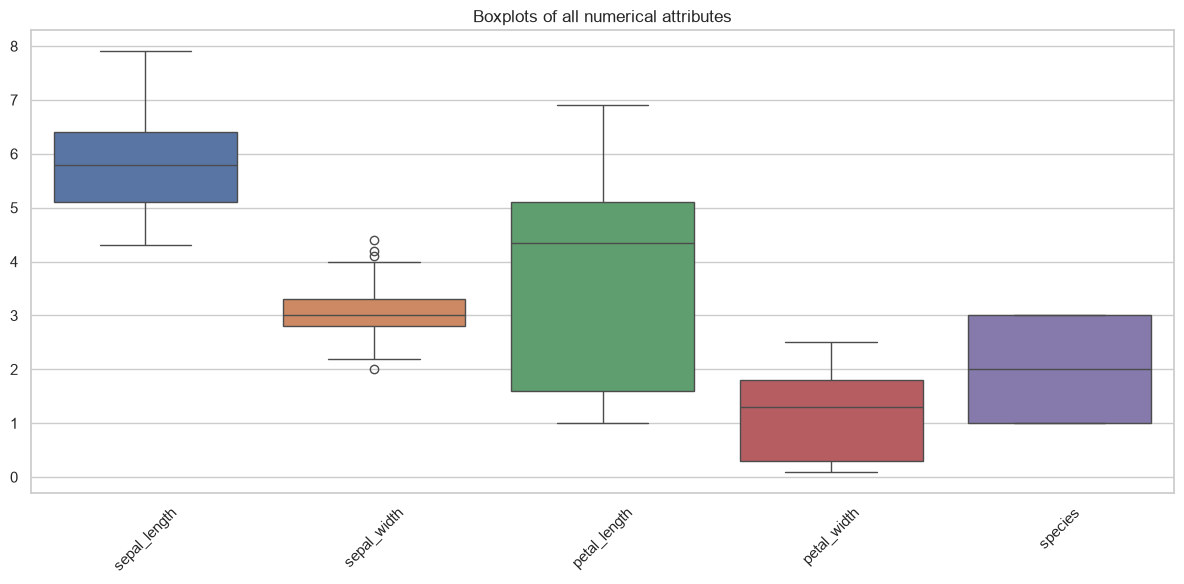

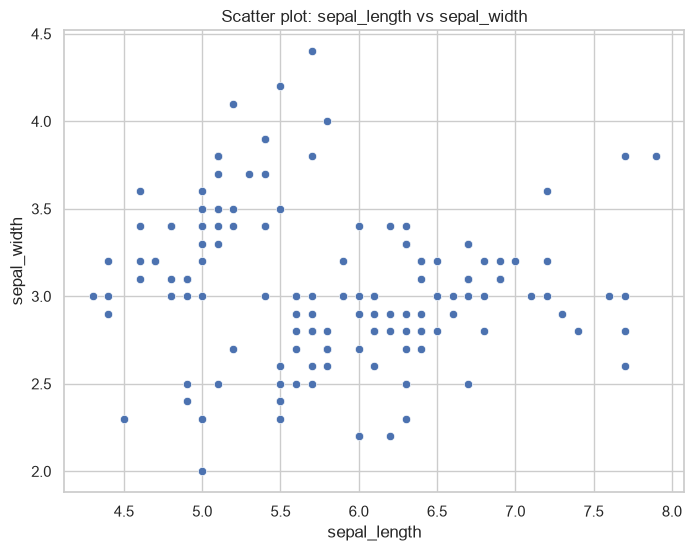

In [28]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=numeric_df) 
plt.xticks(rotation=45) 
plt.title("Boxplots of all numerical attributes")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
col1 = numeric_df.columns[0]
col2 = numeric_df.columns[1]
sns.scatterplot(x=col1, y=col2, data=df)
plt.title(f"Scatter plot: {col1} vs {col2}")
plt.xlabel(col1)
plt.ylabel(col2)
plt.show()

In [24]:
print("descriptive statistics")
for col in numeric_df.columns:
    mode_val = df[col].mode()[0]
    mean_val = df[col].mean()
    median_val = df[col].median()
    print(f"attribute: {col}")
    print(f"  mode: {mode_val} | mean: {mean_val:.2f} | median: {median_val:.2f}")
    print("-" * 30)


descriptive statistics
attribute: sepal_length
  mode: 5.0 | mean: 5.84 | median: 5.80
------------------------------
attribute: sepal_width
  mode: 3.0 | mean: 3.05 | median: 3.00
------------------------------
attribute: petal_length
  mode: 1.5 | mean: 3.76 | median: 4.35
------------------------------
attribute: petal_width
  mode: 0.2 | mean: 1.20 | median: 1.30
------------------------------
attribute: species
  mode: 1 | mean: 2.00 | median: 2.00
------------------------------


In [23]:
numeric_df = df.select_dtypes(include=['number'])
print("\n")
print("key numbers")
key_numbers = numeric_df.describe().loc[['min', 'max', '50%', '25%', '75%']]
key_numbers.index = ['Minimum', 'Maximum', 'Médiane (50%)', 'Premier quartile (Q1)', 'Troisième quartile (Q3)']
display(key_numbers)




key numbers


,sepal_length,sepal_width,petal_length,petal_width,species
Minimum,4.3,2.0,1.00,0.1,1.0
Maximum,7.9,4.4,6.90,2.5,3.0
Médiane (50%),5.8,3.0,4.35,1.3,2.0
Premier quartile (Q1),5.1,2.8,1.60,0.3,1.0
Troisième quartile (Q3),6.4,3.3,5.10,1.8,3.0


In [22]:
df.info()
print(f"number of instances (rows): {df.shape[0]}")
print(f"number of attributes (columns): {df.shape[1]}")
print("\n")
print("attribute names and types:")
print(df.dtypes)


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
number of instances (rows): 150
number of attributes (columns): 5


attribute names and types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species           int64
dtype: object


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
sns.set_theme(style="whitegrid")
# load data
df = pd.read_csv('iris.csv')
df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
